# Load data and train simple model

In [2]:


import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
import torch.optim as optim
import pandas as pd
import numpy as np
from PIL import Image

from pathlib import Path

class ImageSegmentationDataset(Dataset):
    @staticmethod
    def convert_mask(mask_rgb, color_to_class):
        mask = np.full(mask_rgb.shape[:2], 255, dtype=np.int64)

        for color, class_id in color_to_class.items():
            pixels = np.all(mask_rgb == color, axis=-1)
            mask[pixels] = class_id

        return mask

    def __init__(self, image_path, mask_path, transform=None,is_train=True):

        #TO DO: Upiększyć jakoś xd
        self.COLOR_TO_CLASS = {(np.uint8(0), np.uint8(0), np.uint8(0)): 0,
               (np.uint8(0), np.uint8(0), np.uint8(70)): 1,
               (np.uint8(0), np.uint8(0), np.uint8(90)): 2,
               (np.uint8(0), np.uint8(0), np.uint8(110)): 3,
               (np.uint8(0), np.uint8(0), np.uint8(142)): 4,
               (np.uint8(0), np.uint8(0), np.uint8(230)): 5,
               (np.uint8(0), np.uint8(60), np.uint8(100)): 6,
               (np.uint8(0), np.uint8(80), np.uint8(100)): 7,
               (np.uint8(70), np.uint8(70), np.uint8(70)): 8,
               (np.uint8(70), np.uint8(130), np.uint8(180)): 9,
               (np.uint8(81), np.uint8(0), np.uint8(81)): 10,
               (np.uint8(102), np.uint8(102), np.uint8(156)): 11,
               (np.uint8(107), np.uint8(142), np.uint8(35)): 12,
               (np.uint8(111), np.uint8(74), np.uint8(0)): 13,
               (np.uint8(119), np.uint8(11), np.uint8(32)): 14,
               (np.uint8(128), np.uint8(64), np.uint8(128)): 15,
               (np.uint8(150), np.uint8(100), np.uint8(100)): 16,
               (np.uint8(152), np.uint8(251), np.uint8(152)): 17,
               (np.uint8(153), np.uint8(153), np.uint8(153)): 18,
               (np.uint8(180), np.uint8(165), np.uint8(180)): 19,
               (np.uint8(190), np.uint8(153), np.uint8(153)): 20,
               (np.uint8(220), np.uint8(20), np.uint8(60)): 21,
               (np.uint8(220), np.uint8(220), np.uint8(0)): 22,
               (np.uint8(230), np.uint8(150), np.uint8(140)): 23,
               (np.uint8(244), np.uint8(35), np.uint8(232)): 24,
               (np.uint8(250), np.uint8(170), np.uint8(30)): 25,
               (np.uint8(250), np.uint8(170), np.uint8(160)): 26,
               (np.uint8(255), np.uint8(0), np.uint8(0)): 27}

        self.transform = transform
        image_path=Path(image_path)
        mask_path=Path(mask_path)

        #Jelsi zbiór jest mały i można szybko za jednym razem wczytać, inaczej __getitem__ powinien wczytywać pliki batchami

        image_files=sorted(list(image_path.glob("*.png")))
        mask_files=sorted(list(mask_path.glob("*.png")))

        #Do testowania żeby nie czekać długo
        image_files=image_files[:50]
        mask_files=mask_files[:50]

        images_np=[np.array(Image.open(img).convert("RGB")) for img in image_files]

        images_np=np.array(images_np)

        masks_np = []

        for img in mask_files:
            mask_rgb = np.array(Image.open(img).convert("RGB"))

            mask = self.convert_mask(mask_rgb, self.COLOR_TO_CLASS)

            masks_np.append(mask)

        masks_np = np.array(masks_np)

        self.masks = torch.as_tensor(masks_np, dtype=torch.int64)

        #permute for dims for Conv1d etc

        self.images = torch.as_tensor(images_np,dtype=torch.float32).permute(0, 3, 1, 2)/255.0

        print(f"Loaded {len(self.images)}, shape is: {self.images.shape}")
        print(f"Loaded {len(self.masks)}, shape is: {self.masks.shape}")


    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image=self.images[idx]
        mask=self.masks[idx]
        if self.transform:
            #TO DO: apply transform
            pass

        return image,mask

#klasa pomocnicza-wykonuje dwa sploty 2D, a po każdym stosuje normalizację i funkcję aktywacji.
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class SimpleUNet(nn.Module):
    def __init__(self, in_ch, num_classes):
        super().__init__()

        # Enkoder
        self.init_conv = DoubleConv(in_ch, 64)

        self.down1 = nn.Sequential(
            nn.MaxPool2d(2, 2),
            DoubleConv(64, 128)
        )

        self.down2 = nn.Sequential(
            nn.MaxPool2d(2, 2),
            DoubleConv(128, 256)
        )

        # Dekoder
        self.up1 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )
        self.conv_up1 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )
        self.conv_up2 = DoubleConv(128, 64)

        # Wyjście
        self.out_conv = nn.Conv2d(
            64, num_classes, kernel_size=1
        )

    def forward(self, x):
        # Enkoder
        x1 = self.init_conv(x)  # 64 kanały
        x2 = self.down1(x1)     # 128 kanałów
        x3 = self.down2(x2)     # 256 kanałów

        # Dekoder + skip connections
        x = self.up1(x3)        # 128 kanałów

        # Skip connection - łączymy wynik dekodera z x2 z enkoderem.

        x = torch.cat([x, x2], dim=1)  # 256 kanałów
        x = self.conv_up1(x)    # 128 kanałów

        x = self.up2(x)         # 64 kanały
        x = torch.cat([x, x1], dim=1)  # 128 kanałów
        x = self.conv_up2(x)    # 64 kanały

        return self.out_conv(x)


train_dataset= ImageSegmentationDataset("data/train/image/","data/train/mask/")
#val_dataset= ImageSegmentationDataset("data/val/img/","data/val/mask/")


train_loader = DataLoader(train_dataset, batch_size=4, shuffle=False)



Loaded 50, shape is: torch.Size([50, 3, 256, 512])
Loaded 50, shape is: torch.Size([50, 256, 512])


In [7]:

n_classes=len(train_dataset.COLOR_TO_CLASS)
print(f"{n_classes} klas")
device='cuda' if torch.cuda.is_available() else 'cpu'

print(f"device is: {device}")

model = SimpleUNet(in_ch=3,num_classes=n_classes).to(device)

Loss = nn.CrossEntropyLoss(ignore_index=255)
optimizer = optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)


for epoch in range(1, 10):
    epoch_loss = 0
    model.train()
    for images,masks in train_loader:

        images=images.to(device)
        masks=masks.to(device)

        preds = model(images)

        loss = Loss(preds, masks)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()*images.size(0)
    print(f"Epoch {epoch}, loss: {epoch_loss/len(train_loader.dataset)}")


    #TO DO: validation
    '''
    model.eval()
    with torch.no_grad():
        for  in val_loader:
    '''

torch.save(model.state_dict(), "models/model1.pt")
print(f"Model saved to {"models/model1.pt"}")


28 klas
device is: cuda
Epoch 1, loss: 2.6409811687469484
Epoch 2, loss: 2.0057391262054445
Epoch 3, loss: 1.638162498474121
Epoch 4, loss: 1.4148732042312622
Epoch 5, loss: 1.2817075109481813
Epoch 6, loss: 1.1845203685760497
Epoch 7, loss: 1.129584927558899
Epoch 8, loss: 1.0717772912979127
Epoch 9, loss: 1.034547166824341
Model saved to models/model1.pt


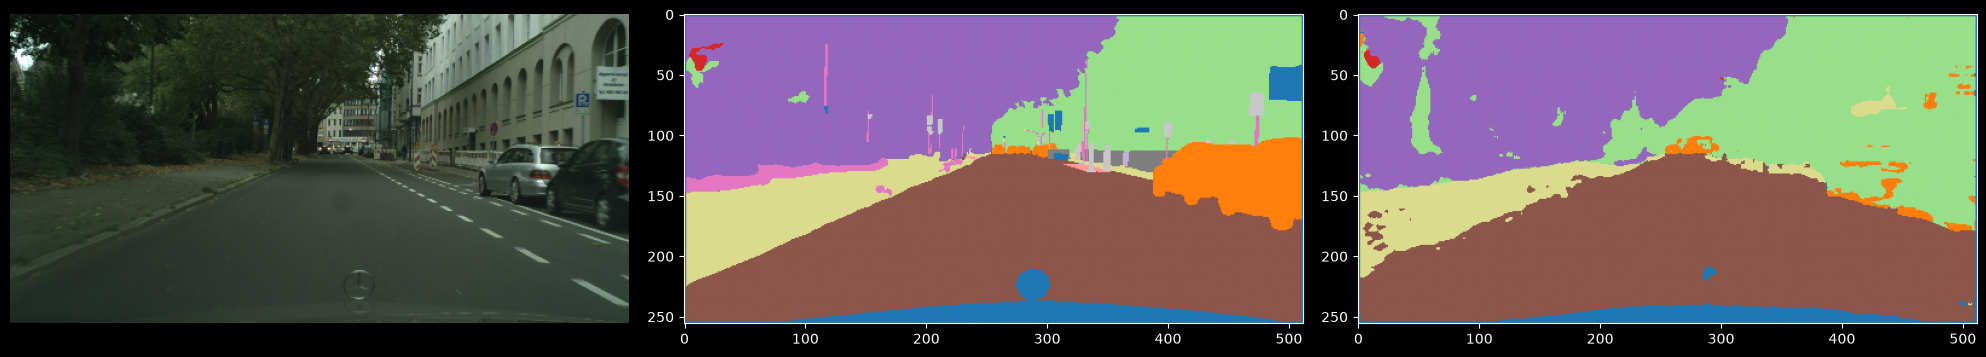

In [9]:
import matplotlib.pyplot as plt


model = SimpleUNet(in_ch=3,num_classes=n_classes)#.to(device) żeby robić inferencje na gpu ale dla 1 obrazu to bez sensu

state_dict = torch.load('models/model1.pt')

model.load_state_dict(state_dict)

model.eval()

img,label=train_dataset[2]
with torch.no_grad():
    preds = model(img.unsqueeze(dim=0))

pred_mask=torch.argmax(preds,dim=1).squeeze().cpu().numpy()

img_to_show=img.permute(1, 2, 0).cpu().numpy()
label_to_show=label.cpu().numpy()

#TO DO: Ładniejszy obrazek

fig,axes=plt.subplots(1,3,figsize=(20,10))
axes[0].imshow(img_to_show)
axes[0].axis('off')
axes[1].imshow(label_to_show,cmap="tab20",vmin=0,vmax=n_classes)
axes[2].imshow(pred_mask,cmap="tab20",vmin=0,vmax=n_classes)
plt.tight_layout()
plt.show()



#to ze zbioru treningowego!